# Clasificación estelar D2: SDSS, Optuna y MLflow

Ejecutar después del DAG **process_etl_star_data**. Fuente: SDSS DR17,
consulta `TOP 1000 ... ORDER BY p.objid`; esta muestra ordenada no es aleatoria.

Se reproduce **D2** de `tp-clasificacion-estelar_final.ipynb`: bandas
`u, g, r, i, z` y colores `u-g, g-r, r-i, i-z`; objetivo `class`.
`redshift`, `ra`, `dec` y `objid` no son variables predictoras.
Se eliminan duplicados por objid y mediciones <= -9000, nulas o infinitas.
No se eliminan outliers usando la clase objetivo.

Train/test estratificado 80/20 (semilla 42). El scaler vive dentro del Pipeline
y se ajusta dentro de cada fold. Optuna compara SVM, árbol, Random Forest y KNN
con F1 weighted (multiclase) y 5 folds; test se usa solo tras elegir el ganador.
Cada ejecución abre un run nuevo; no reabre «el último run» ni sobrescribe raw.

Registro: experimento **star type**, modelo **star_type_model_prod**, alias **champion**.
La última celda de registro mueve ese alias a una versión nueva.
Esto no modifica la API de Heart Disease.

## Dependencias y conexión
Ejecutar con el kernel local de Windows y desde `notebook_example/`.
En Docker usar `STAR_MLFLOW_URI=http://mlflow:5000` y
`STAR_S3_ENDPOINT=http://s3:9000`.
Las credenciales pueden venir de variables de entorno; los valores por defecto
corresponden al MinIO de desarrollo del repositorio.
Para una ejecución rápida se puede definir `STAR_N_TRIALS=10` antes de iniciar el kernel;
por defecto se realizan 250 pruebas con un solo proceso.

In [1]:
# Ejecutar si faltan dependencias o MLflow no coincide con el servidor:
# %pip install -r requirements_star.txt
# Después de instalar/cambiar versiones, reiniciar el kernel.

In [2]:
import os
import io
import sys
import json
import hashlib
import platform
from datetime import datetime, timezone
from pathlib import Path
from importlib.metadata import version

import boto3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow
import mlflow.sklearn
import optuna
from mlflow import MlflowClient
from mlflow.models import infer_signature
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

if version('mlflow') != '3.16.1':
    raise RuntimeError('Esta notebook usa MLflow 3.16.1 como el servidor. '
                       'Instalar requirements_star.txt y reiniciar el kernel antes de continuar.')

# Funciona iniciando Jupyter desde notebook_example o desde la raíz del repo.
helper_dir = Path.cwd() if Path('star_workflow.py').exists() else Path.cwd() / 'notebook_example'
sys.path.insert(0, str(helper_dir.resolve()))
from star_workflow import prepare_d2, make_pipeline, BANDS, D2_FEATURES, CLASSES

SEED = 42
N_TRIALS = int(os.getenv('STAR_N_TRIALS', '250'))
if N_TRIALS < 1:
    raise ValueError('STAR_N_TRIALS debe ser positivo')
MLFLOW_URI = os.getenv('STAR_MLFLOW_URI', 'http://localhost:5001')
S3_ENDPOINT = os.getenv('STAR_S3_ENDPOINT', 'http://localhost:9000')
BUCKET = 'data'
RAW_KEY = 'raw/star/starset.csv'
MODEL_NAME = 'star_type_model_prod'
os.environ.setdefault('AWS_ACCESS_KEY_ID', 'minio')
os.environ.setdefault('AWS_SECRET_ACCESS_KEY', 'minio123')
os.environ.setdefault('AWS_DEFAULT_REGION', 'us-east-1')
os.environ['MLFLOW_S3_ENDPOINT_URL'] = S3_ENDPOINT
os.environ['AWS_ENDPOINT_URL_S3'] = S3_ENDPOINT
mlflow.set_tracking_uri(MLFLOW_URI)
experiment = mlflow.set_experiment('star type')
experiment_id = experiment.experiment_id
client = MlflowClient()
s3 = boto3.client('s3', endpoint_url=S3_ENDPOINT)
optuna.logging.set_verbosity(optuna.logging.WARNING)
print('Experimento:', experiment_id, '| trials:', N_TRIALS)
print({p: version(p) for p in ['scikit-learn', 'mlflow', 'optuna', 'pandas', 'numpy']})

Experimento: 1 | trials: 250
{'scikit-learn': '1.7.2', 'mlflow': '3.16.1', 'optuna': '5.0.0', 'pandas': '2.3.3', 'numpy': '2.3.5'}


## Lectura y trazabilidad del CSV
Se conserva `objid` como texto para no perder precisión. Una copia por SHA-256
permite reconstruir el conjunto usado aunque una futura ingesta cambie starset.csv.

In [3]:
response = s3.get_object(Bucket=BUCKET, Key=RAW_KEY)
raw_bytes = response['Body'].read()
dataset_sha256 = hashlib.sha256(raw_bytes).hexdigest()
df_raw = pd.read_csv(io.BytesIO(raw_bytes), dtype={'objid': 'string'})
df_clean = prepare_d2(df_raw)
print('Original:', df_raw.shape, '| Limpio:', df_clean.shape)
display(df_clean['class'].value_counts().rename('cantidad').to_frame())
display(df_clean[BANDS + ['class']].head())

snapshot_key = f'raw/star/snapshots/{dataset_sha256}.csv'
s3.put_object(Bucket=BUCKET, Key=snapshot_key, Body=raw_bytes, ContentType='text/csv')
ingestions = mlflow.search_runs(
    experiment_ids=[experiment_id],
    filter_string=f"tags.stage = 'ingestion' AND tags.`dataset.sha256` = '{dataset_sha256}'",
    max_results=1,
)
ingestion_run_id = None if ingestions.empty else ingestions.iloc[0]['run_id']
print('SHA256:', dataset_sha256, '| run de ingesta:', ingestion_run_id)

Original: (1000, 10) | Limpio: (999, 14)


,cantidad
class,
GALAXY,604
STAR,320
QSO,75


,u,g,r,i,z,class
0,25.92735,20.99570,19.24612,18.56461,18.43049,GALAXY
1,19.38905,18.24496,17.58728,17.20807,16.90905,GALAXY
2,20.14134,19.28787,19.04397,18.96897,18.79573,STAR
3,21.50923,19.69340,18.47973,17.91998,17.55132,GALAXY
4,20.96947,20.29136,19.36779,18.86387,18.45551,GALAXY


SHA256: eee9e1138e12e4a86326ab967d6033bfc7dccd8172de13420350def5a2b312bc | run de ingesta: 18469ec1da294bb2919b6fe3f31770e6


## Preparación D2 y partición
Las diferencias entre bandas son operaciones por fila y no aprenden parámetros.
La normalización se aprende solamente dentro del Pipeline, nunca antes de CV.

In [4]:
X = df_clean[D2_FEATURES].copy()
y = df_clean['class'].astype(str)
if set(y.unique()) != set(CLASSES):
    raise ValueError(f'Se requieren las tres clases {CLASSES}; llegaron {sorted(y.unique())}')
idx_train, idx_test = train_test_split(
    df_clean.index, test_size=.20, random_state=SEED, stratify=y)
X_train, X_test = X.loc[idx_train], X.loc[idx_test]
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
if y_train.value_counts().min() < 5:
    raise ValueError('Cada clase debe tener al menos 5 ejemplos de entrenamiento para CV=5')
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
print('Train:', X_train.shape, '| Test:', X_test.shape)
display(pd.DataFrame({'train': y_train.value_counts(), 'test': y_test.value_counts()}))

prepared_prefix = f'final/star/d2/{dataset_sha256}'
for name, frame in [('X_train', X_train), ('X_test', X_test),
                    ('y_train', y_train.to_frame()), ('y_test', y_test.to_frame())]:
    s3.put_object(Bucket=BUCKET, Key=f'{prepared_prefix}/{name}.csv',
                  Body=frame.to_csv(index=False).encode(), ContentType='text/csv')

Train: (799, 9) | Test: (200, 9)


,train,test
class,,
GALAXY,483,121
STAR,256,64
QSO,60,15


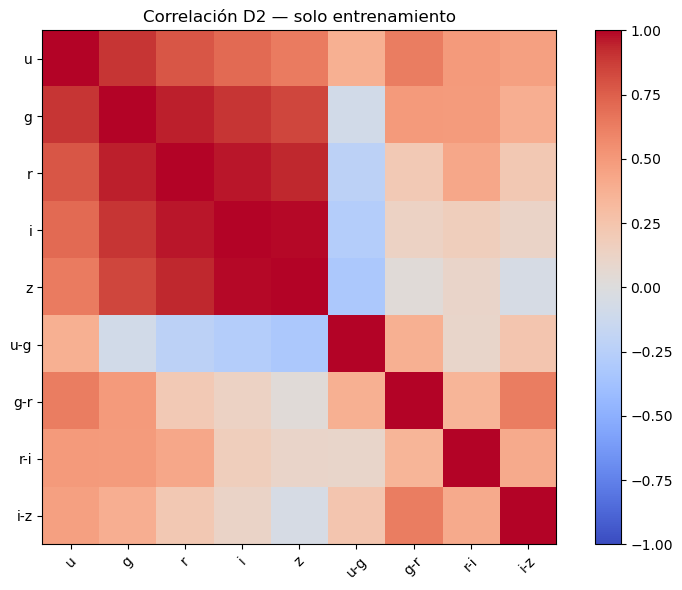

In [5]:
fig_corr, ax = plt.subplots(figsize=(8, 6))
image = ax.imshow(X_train.corr(), vmin=-1, vmax=1, cmap='coolwarm')
ax.set_xticks(range(len(D2_FEATURES)), D2_FEATURES, rotation=45)
ax.set_yticks(range(len(D2_FEATURES)), D2_FEATURES)
ax.set_title('Correlación D2 — solo entrenamiento')
fig_corr.colorbar(image, ax=ax)
fig_corr.tight_layout()
plt.show()

## Optimización y entrenamiento
Cada trial tiene su run hijo y registra sus hiperparámetros y los cinco F1.
El run padre guarda la selección, las métricas finales y el Pipeline completo.
`n_jobs=1` evita saturar Docker/Windows. Optuna tiene semilla fija.
El test no se usa para seleccionar hiperparámetros.

In [6]:
def objective(trial):
    with mlflow.start_run(experiment_id=experiment_id,
                          run_name=f'trial_{trial.number:03d}', nested=True):
        pipeline = make_pipeline(trial)
        mlflow.log_params(trial.params)
        mlflow.set_tags({'stage': 'search', 'feature_set': 'D2'})
        scores = cross_val_score(pipeline, X_train, y_train, cv=cv,
                                 scoring='f1_weighted', n_jobs=1, error_score='raise')
        mlflow.log_metric('cv_f1_weighted', float(scores.mean()))
        mlflow.log_metric('cv_f1_std', float(scores.std()))
        for fold, score in enumerate(scores, 1):
            mlflow.log_metric(f'fold_{fold}_f1_weighted', float(score))
        return float(scores.mean())


def champion_callback(study, trial):
    if study.best_trial.number == trial.number:
        print(f'Trial {trial.number}: nuevo mejor F1 CV = {trial.value:.4f}')

In [7]:
run_name = 'best_star_d2_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ')
with mlflow.start_run(experiment_id=experiment_id, run_name=run_name) as parent_run:
    parent_run_id = parent_run.info.run_id
    mlflow.set_tags({'stage': 'training', 'feature_set': 'D2',
                     'dataset.sha256': dataset_sha256,
                     'ingestion_run_id': ingestion_run_id or 'not_found',
                     'optimizer': 'optuna', 'target': 'class'})
    mlflow.log_params({'n_trials': N_TRIALS, 'cv_folds': 5, 'seed': SEED,
                       'test_size': .2, 'scoring': 'f1_weighted',
                       'dataset_uri': f's3://{BUCKET}/{snapshot_key}',
                       'train_rows': len(X_train), 'test_rows': len(X_test)})
    mlflow.log_dict({'bands': BANDS, 'features': D2_FEATURES, 'classes': CLASSES,
                     'colors': ['u-g', 'g-r', 'r-i', 'i-z'],
                     'excluded': ['objid', 'ra', 'dec', 'redshift'],
                     'missing_magnitude_threshold': -9000}, 'preprocessing/d2.json')
    mlflow.log_dict({'train_objid': df_clean.loc[idx_train, 'objid'].astype(str).tolist(),
                     'test_objid': df_clean.loc[idx_test, 'objid'].astype(str).tolist()},
                    'data/split_objids.json')
    mlflow.log_dict({p: version(p) for p in ['scikit-learn', 'mlflow', 'optuna', 'pandas', 'numpy']},
                    'environment/versions.json')
    mlflow.log_figure(fig_corr, 'plots/correlation_d2.png')
    study = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=SEED))
    study.optimize(objective, n_trials=N_TRIALS, n_jobs=1, callbacks=[champion_callback])
    mlflow.log_params(study.best_params)
    mlflow.log_metric('best_cv_f1_weighted', study.best_value)
    mlflow.log_table(study.trials_dataframe(), 'search/trials.json')

print('Run:', parent_run_id)
print('Mejor combinación:', study.best_params)
print('F1 CV:', study.best_value)

🏃 View run trial_000 at: http://localhost:5001/#/experiments/1/runs/c2a4d597fa084ae4bde6e6d558cf706c
🧪 View experiment at: http://localhost:5001/#/experiments/1
Trial 0: nuevo mejor F1 CV = 0.5989
🏃 View run trial_001 at: http://localhost:5001/#/experiments/1/runs/3bbc53bf3e504477b51e02ffc85d54f6
🧪 View experiment at: http://localhost:5001/#/experiments/1
Trial 1: nuevo mejor F1 CV = 0.7945
🏃 View run trial_002 at: http://localhost:5001/#/experiments/1/runs/94e17d343d91439cbc23e986a47d4f76
🧪 View experiment at: http://localhost:5001/#/experiments/1
Trial 2: nuevo mejor F1 CV = 0.8132
🏃 View run trial_003 at: http://localhost:5001/#/experiments/1/runs/b1fc1a65675f4647bdc438d2b6231b8d
🧪 View experiment at: http://localhost:5001/#/experiments/1
🏃 View run trial_004 at: http://localhost:5001/#/experiments/1/runs/08c40a15aef944818366964b6da08d9c
🧪 View experiment at: http://localhost:5001/#/experiments/1
Trial 4: nuevo mejor F1 CV = 0.8484
🏃 View run trial_005 at: http://localhost:5001/#/ex

## Entrenar y guardar el ganador

Esta celda reutiliza exclusivamente el `parent_run_id` creado en la búsqueda.
Si falla el guardado por un problema de conexión, se puede reejecutar esta celda
sin repetir las 250 pruebas. Los datos D2 siguen sin escalar y el Pipeline
se ajusta desde cero con los mismos parámetros; no sobrescribe el CSV raw.

2026/11/16 10:05:05 WARNING mlflow.sklearn: Saving scikit-learn models in the pickle or cloudpickle format requires exercising caution because these formats rely on Python's object serialization mechanism, which can execute arbitrary code during deserialization. The recommended safe alternative is the 'skops' format. For more information, see: https://scikit-learn.org/stable/model_persistence.html


🏃 View run best_star_d2_20261116T125210_292926Z at: http://localhost:5001/#/experiments/1/runs/7f32684d705d448783a53889ebd9c989
🧪 View experiment at: http://localhost:5001/#/experiments/1
Run: 7f32684d705d448783a53889ebd9c989
Mejor combinación: {'classifier': 'RandomForest', 'rf_max_depth': 16, 'rf_n_estimators': 76}
F1 CV: 0.8569681152188251


test_accuracy              0.860000
test_precision_weighted    0.856494
test_recall_weighted       0.860000
test_f1_weighted           0.855751
test_f1_macro              0.762582
dtype: float64

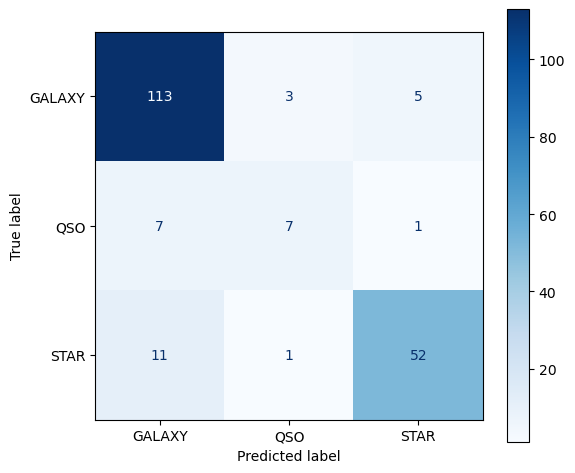

In [9]:
with mlflow.start_run(run_id=parent_run_id):
    model = make_pipeline(optuna.trial.FixedTrial(study.best_params))
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    test_metrics = {
        'test_accuracy': accuracy_score(y_test, y_pred),
        'test_precision_weighted': precision_score(y_test, y_pred, average='weighted', zero_division=0),
        'test_recall_weighted': recall_score(y_test, y_pred, average='weighted', zero_division=0),
        'test_f1_weighted': f1_score(y_test, y_pred, average='weighted', zero_division=0),
        'test_f1_macro': f1_score(y_test, y_pred, average='macro', zero_division=0),
    }
    mlflow.log_metrics(test_metrics)
    report = classification_report(y_test, y_pred, labels=CLASSES, output_dict=True, zero_division=0)
    mlflow.log_dict(report, 'evaluation/classification_report.json')
    fig_cm, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=CLASSES, ax=ax, cmap='Blues')
    fig_cm.tight_layout()
    mlflow.log_figure(fig_cm, 'evaluation/confusion_matrix.png')
    scaler = model.named_steps['scaler']
    mlflow.log_dict({'feature_names': D2_FEATURES, 'mean': scaler.mean_.tolist(),
                     'scale': scaler.scale_.tolist()}, 'preprocessing/scaler.json')
    # Pipeline sklearn estándar: no depende de star_workflow para inferencia D2.
    model_info = mlflow.sklearn.log_model(
        sk_model=model, name='model', signature=infer_signature(X_train, model.predict(X_train)),
        input_example=X_train.head(3), serialization_format='cloudpickle',
        metadata={'feature_set': 'D2', 'dataset_sha256': dataset_sha256})
    model_uri = model_info.model_uri

print('Run:', parent_run_id)
print('Mejor combinación:', study.best_params)
print('F1 CV:', study.best_value)
display(pd.Series(test_metrics))
plt.show()

## Comprobar persistencia y registrar champion
Primero se recarga el artefacto y se comprueba que conserva sus predicciones.
Luego se registra una versión nueva (el nombre puede existir) y se mueve
`champion`. Las versiones anteriores se conservan. No se reutilizan runs
de ETL ni se cambia el alias de Heart Disease.

La etiqueta champion identifica al candidato seleccionado en esta búsqueda;
no implica una validación para uso científico ni una comparación automática
contra un champion anterior. Revisar las métricas antes de ejecutar el registro.

In [11]:
loaded = mlflow.sklearn.load_model(model_uri)
np.testing.assert_array_equal(loaded.predict(X_test), model.predict(X_test))
print('Modelo recargado: predicciones idénticas')
display(pd.DataFrame({'real': y_test.head(5),
                       'prediccion': loaded.predict(X_test.head(5))}))

Modelo recargado: predicciones idénticas


,real,prediccion
474,STAR,GALAXY
445,GALAXY,GALAXY
336,GALAXY,GALAXY
143,GALAXY,GALAXY
912,STAR,STAR


In [12]:
# Esta celda crea una versión nueva y actualiza el alias del modelo estelar.
registered = mlflow.register_model(model_uri=model_uri, name=MODEL_NAME,
                                    await_registration_for=300)
client.set_model_version_tag(MODEL_NAME, registered.version, 'feature_set', 'D2')
client.set_model_version_tag(MODEL_NAME, registered.version, 'training_run_id', parent_run_id)
client.set_model_version_tag(MODEL_NAME, registered.version, 'dataset_sha256', dataset_sha256)
client.set_model_version_tag(MODEL_NAME, registered.version, 'test_f1_weighted', str(test_metrics['test_f1_weighted']))
client.set_registered_model_alias(MODEL_NAME, 'champion', registered.version)
assert client.get_model_version_by_alias(MODEL_NAME, 'champion').version == registered.version
print(f'Champion: models:/{MODEL_NAME}@champion — versión {registered.version}')

Successfully registered model 'star_type_model_prod'.
2026/11/16 10:17:53 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: star_type_model_prod, version 1
Created version '1' of model 'star_type_model_prod'.


Champion: models:/star_type_model_prod@champion — versión 1


## Predicción desde el registro
El Pipeline espera las nueve columnas D2 sin escalar. Si llegan cinco bandas,
primero se calculan sus cuatro diferencias; no se ajusta otro scaler.
La salida es una etiqueta `GALAXY`, `QSO` o `STAR`, no un diagnóstico médico.

In [ ]:
champion = mlflow.sklearn.load_model(f'models:/{MODEL_NAME}@champion')
new_bands = pd.DataFrame([{'u': 20.1, 'g': 19.3, 'r': 18.8, 'i': 18.5, 'z': 18.3}])
new_d2 = new_bands.copy()
for left, right in zip(BANDS[:-1], BANDS[1:]):
    new_d2[f'{left}-{right}'] = new_d2[left] - new_d2[right]
print(champion.predict(new_d2[D2_FEATURES]))